# Phase 5: Exploratory improvements

We tried, exploratorily, to improve on the locked models of Phase 3, scoring every change on 135 validation pairs from 14 donors. In track A, none of five changes to the strictly unpaired CycleGAN (M1) moved it beyond the unpaired accuracy–realism frontier, the best realism that blends of simple unpaired baselines reach at each accuracy. The best change, removing the identity loss, did not hold up on three fresh seeds (gain in margin over M1 +0.010 ± 0.025, mean ± SD over 3 seeds, averaged over directions), and no change raised the sample-specific component of the generators' moves in both directions. In track B, composition labels from networks that never saw the labeled row's donor keep about the same composition gain over M1 as the locked networks (marker-probe composition R² +0.141, 95% CI 0.099–0.222, and +0.200, 95% CI 0.099–0.383, against +0.137 and +0.216). The gain depends on how many paired donors produce the labels: labels from 8 donors already help bulk → single-cell (+0.117, 95% CI 0.029–0.251), while in single-cell → bulk labels from 4 or 8 donors hurt (−0.168, 95% CI −0.305 to −0.100, and −0.074, 95% CI −0.144 to −0.026) and those from 16 donors break even. These are validation results of an exploratory phase; the hypotheses of Phase 3 apply only to the locked models.

## 1. Aim

Phase 4 found that the strictly unpaired CycleGAN (M1) sits on the unpaired accuracy–realism frontier because its discriminator buys realism while its moves away from the baseline map it starts at are mostly orthogonal to the correction each sample needs. It also found that the weakly paired model (M2) owes part of its composition gain to labels that were close to the paired truth. Here we try to change the direction of M1's moves (track A), and we measure how much honest pair information, that is, labels from networks that never saw the labeled sample's donor, composition supervision needs (track B). Settings were chosen on the same validation donors as before, so the results are exploratory; the hypotheses of Phase 3 apply only to the locked models.

## 2. Data

- **Training: halving 0 of the training split** (582 pairs, 68 donors), as in Phases 3–4. A halving divides the training donors into two donor-disjoint halves, A and B (Phase 1, §3.5). The translation models saw the single-cell pseudobulk profiles of half A (33 donors, 288 draws) and the whole-blood bulk profiles of half B (35 donors, 294 draws), and no pair; the weakly paired models use pair information only through the bulk composition network $C_B$ in their task loss.
- **Bulk composition networks for track B** (the Phase 2 configuration of $C_B$), trained only on training donors' pairs:
  - cross-fitted over the 68 training donors in 5 donor-grouped, age-stratified folds, each network leaving one fold out;
  - cross-fitted within half A (5 folds);
  - on the pairs of the first k donors (k = 4, 8, 16) of a 16-donor, age-balanced pool of half-A donors drawn per seed, so the sets are nested.
- **Single-cell composition network.** $C_S$, which needs no pairs, is the network trained on half A's single-cell profiles (Phase 4) throughout track B.
- **Scoring: validation** (135 pairs, 14 donors), with the Phase 1 evaluators, which are fit on training targets only. The test split is not used.

## 3. Methods

**Notation and metrics** (defined in full in Phase 1, §3, Phase 3, §3, and Phase 4, §3). $x_S$ and $x_B$ are single-cell pseudobulk and whole-blood bulk profiles (log(1 + CP10k) on the 5,000-gene panel), $G_{S\to B}$ and $G_{B\to S}$ the two generators, and $c^*$ the measured composition over six cell-type classes. For a translation $\hat y$ of a validation source whose real partner is $y$:

- **Centered R²** (accuracy): $1 - \lVert \hat y - y\rVert^2 / \lVert y - \mu\rVert^2$, with $\mu$ the per-gene training mean of the target domain, reported as the median over validation pairs; higher is better.
- **Realism**: $1 - 2\,\lvert \text{AUROC} - 0.5 \rvert$, where the AUROC is that of a classifier two-sample test (C2ST; Lopez-Paz and Oquab, 2017): a logistic regression on the top 10 target principal-component scores and their squares, cross-validated in folds grouped by donor, that separates translations from real validation targets. 1 means indistinguishable, 0 perfectly separable. This is the realism measure of Phase 3's hypothesis H1 (the **H1 measure**).
- **Unpaired frontier and margin**: the frontier $F(r)$ is the highest realism reached, at centered R² of at least $r$, by any blend of two of mean shift, ComBat (Johnson et al., 2007), CORAL (Sun et al., 2016) and the training-target mean, all fit on the same training halves. A model at accuracy $r$ and realism $s$ has margin $s - F(r)$; a positive margin means that no blend of unpaired baselines is as realistic at that accuracy.
- **Composition R²**: the mean over the six classes of the per-class R² of a composition readout against $c^*$. The **marker probe** is a ridge regression of composition on 28 lineage marker genes (Phase 2), independent of the composition networks that M2 trains against. The **composition networks** $C_S$ and $C_B$ (Phase 2) read composition from single-cell and bulk profiles; $C_B$ is trained on pairs.
- **Start**: each generator starts exactly at an affine baseline map $s(x)$, mean shift in single-cell → bulk and ComBat in bulk → single-cell (Phase 3, §3.1).
- **Sample-specific component** (Phase 4, §4.5): for the move from the start $\delta = G(x) - s(x)$ and the needed correction $r = y - s(x)$, the median over validation samples of $\cos(\delta, r)$ minus the same median with $y$ replaced by a real profile of another donor. Part of any move toward real profiles points along the needed correction whatever the partner; the difference is the part that is specific to the sample.

**Models.** M1 is a CycleGAN (Zhu et al., 2017) with the least-squares adversarial loss (Mao et al., 2017), the cycle-consistency loss at weight 20 and the identity loss (each generator applied to a profile of its own target domain should return it unchanged) at weight 10. M2 adds the composition task loss (Hoffman et al., 2018) at weight 10, with two terms: the single-cell → bulk term compares $C_B$'s reading of the translated profile with the measured composition, and the bulk → single-cell term compares $C_S$'s reading of the translated profile with $C_B$'s reading of the bulk input (a pseudo-label). Both are the locked Phase 3 settings.

### 3.1 Protocol

- **Averaged weights.** Every run kept an exponential moving average of the generator weights (decay 0.999; Phase 4, §4.7), and the averaged weights give every readout.
- **References.** The locked M1 and M2 were retrained on seeds 6–8, and M1 also on seeds 9–11 for the confirmation. Seeds 0–5 informed the design.
- **Primary readouts.** The **last-quarter readout** of a run is its mean over the 11 evaluations at steps 15,000–20,000 of the margin, centered R², realism and marker-probe composition R², per direction.
- **Kept checkpoints.** The averaged weights saved at steps 15,000, 17,500 and 20,000; the sample-specific component and the confidence intervals are computed on them, pooled over checkpoints and seeds.
- **Uncertainty.** SDs over 3 seeds for every readout. For differences in centered R² and marker-probe composition R², also donor-bootstrap 95% CIs (1,000 resamples of the 14 validation donors) at the kept checkpoints. The CIs cover donor sampling only, not training noise; realism and margin have seed SDs only, as in Phase 4.
- **Equivalence check.** With every new option at its default, the code must reproduce the locked M1 of Phase 3 on seeds 0–2: the same generators and the same margin at every evaluation.

### 3.2 Track A: the strictly unpaired model

| Setting | Change |
|---|---|
| A-idoff | Identity loss off, in both directions (the control) |
| A-idS | Identity loss off for the single-cell → bulk generator only |
| A-anc | Start-anchored identity loss: on the other domain's input, the target is the start's output instead of the input, $\lVert G_{S\to B}(x_B) - s_{S\to B}(x_B)\rVert_1 + \lVert G_{B\to S}(x_S) - s_{B\to S}(x_S)\rVert_1$, weight 10 |
| A-dist | Distance preservation (Benaim and Wolf, 2017): within each batch, the pairwise distances between translations should match those between the start's outputs, each set standardized by its own batch mean and SD, so only relative geometry is constrained |
| A-bn | Bottleneck residual: the generator's residual branch passes through 8 units (5,000 → 512 → 8 → 5,000) |

- **Weight of A-dist.** Set before any run from Phase 4's full-model runs (seeds 3–5, steps 15,000–20,000), so that the distance term is about 1× the adversarial term at M1's plateau.
- **Pre-check.** A second weight, 0.1× the adversarial term, would also run only if the start's pairwise distances correlated with the true partners' by at least 0.3 and by at least 0.05 more than M1's did (means over the two directions; thresholds fixed before computing them).
- **A-both** (the best loss change combined with the bottleneck) runs only if both beat A-idoff on mean last-quarter margin over directions.
- **Confirmation.** The best setting by mean last-quarter margin was re-run on seeds 9–11 next to M1. It counts as **promising** only if all three hold:
  - the mean over directions of its per-seed paired margin difference from M1 exceeds 2 SDs of that difference;
  - no direction is worse than M1 by more than 1 SD;
  - its margin is above 0 in at least one direction.

### 3.3 Track B: how much honest pair information composition supervision needs

**Cross-fitting** splits the training donors into folds and trains one network per fold on the other folds; each training row is then read by the network that never saw its donor. The **label budget k** is the number of half-A donors whose bulk pairs train $C_B$.

| Setting | Bulk composition network in the task loss |
|---|---|
| M2 (reference) | The locked $C_B$, trained on all 582 training pairs (it saw every training donor) |
| B-cf | Cross-fitted over 68 donors: every training row, in both task terms, is read by the network that left its donor out |
| B-k (k = 4, 8, 16) | Trained on the first k pool donors. The single-cell → bulk term uses only the other 17 half-A donors' rows (144 rows), so no label network reads a donor it was trained on |
| B-k33 | All 33 half-A donors: the single-cell → bulk term (all 288 rows) is read by networks cross-fitted within half A; the bulk-side pseudo-labels come from the network trained on all of half A. Not on the same footing as k = 4–16 |

We compared five track A and five track B settings, each on 3 seeds. As paired comparators, we trained ridge (k ≥ 8) and ridge + spread (k ≥ 16) on the same k half-A donors' pairs. The cross-validation inside each needs at least 5 donors, and ridge + spread needs at least 2 donors per held-out fold, so there is no comparator at k = 4.

## 4. Results

The first code cell records the setup stamp, pins the CPU threads, sets up the caches and loads the validation data, evaluators and frontier of halving 0.

In [1]:
import os, sys, json, warnings
from pathlib import Path
os.environ["PYTHONWARNINGS"] = "ignore:An input array is constant"   # inherited by the worker processes
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import hashlib, pickle
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning
from scipy.stats import ConstantInputWarning

from dgm import paths
from dgm import ablation as ab
from dgm import composition as comp
from dgm import labels as lb
from dgm import grid, translation as tr
from dgm.frontier import envelope
from dgm.models import load_frozen, pairs_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", category=ConstantInputWarning)
info = setup(seed=0, notebook="phase5_exploratory.ipynb")
comp.deterministic()

RESULTS, FIG = paths.results_dir(5), paths.results_dir(5, "figures")
CACHE = paths.PROCESSED / "phase5"; CACHE.mkdir(parents=True, exist_ok=True)
MOD5, REG5 = paths.REPO / "data" / "models" / "phase5", RESULTS / "models.json"
WORKERS = 6
SEEDS, CONF_SEEDS, EQ_SEEDS = (6, 7, 8), (9, 10, 11), (0, 1, 2)
KEEP = (15000, 17500, 20000)
P3 = json.loads((paths.results_dir(3) / "models.json").read_text())
M1 = tr.config(lambda_cyc=20.0, identity=True)                # the locked settings (Phase 3)
M2 = tr.config(lambda_cyc=20.0, identity=True, lambda_task=10.0)
DEF = dict(ema=0.999, keep_states=KEEP)                       # weight averaging on, generators kept for the readouts

def show_caption(name):
    f = FIG / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

ctx0 = tr.SoundLife(0)
P, va = ctx0.pairs, ctx0.va
tr_idx = P.idx("train")

commit: e7ab7c1 | notebook_source: 9ced0510da48 (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: True


### 4.1 Composition networks for honest labels

**Honest labels are much noisier than the locked network's, and labels from 4 donors are no better than predicting the mean composition.**

**Table 5.1.** Composition R² (mean over the six classes of the per-class R²) of track B's bulk composition networks: on half B's bulk profiles (294 draws, 35 donors), where their readings are the weakly paired model's bulk-side labels, and on the 135 validation bulk profiles (14 donors). For the cross-fitted networks, the half-B value reads each row with the network that never saw its donor, and the validation value is the mean over the five fold networks. The k-donor networks have one row per seed (one donor draw per seed); the last row is the network trained on all 33 half-A donors (Phase 4).

In [2]:
# Track B's bulk composition networks (Phase 2 configuration), trained before any run since their registry enters the code key:
# cross-fitted over the 68 training donors, cross-fitted within half A, and on k = 4, 8, 16 donors of a 16-donor half-A pool per seed.
reg = json.loads(REG5.read_text()) if REG5.exists() else {}
if "C_bulk_cf68_folds" not in reg:
    lb.train_crossfit(P, tr_idx, "C_bulk_cf68", MOD5, REG5)
if "C_bulk_cfA_folds" not in json.loads(REG5.read_text()):
    lb.train_crossfit(P, ctx0.half_a, "C_bulk_cfA", MOD5, REG5)
for s in SEEDS:
    if f"pool_s{s}" not in json.loads(REG5.read_text()):
        lb.train_budget(P, ctx0.half_a, s, MOD5, REG5)
from tests.test_phase5 import test_label_networks_never_see_their_rows
test_label_networks_never_see_their_rows()                     # registry checks: no network saw its own rows' donors
E5 = json.loads(REG5.read_text())
digest = pairs_hash(P)
ld = lambda name: load_frozen(name, MOD5, REG5, ctx0.genes, ctx0.classes, digest)
def read(net, x):
    with torch.no_grad():
        return net(torch.as_tensor(x, dtype=torch.float32)).numpy()
hb, ha = ctx0.half_b, ctx0.half_a
C = P.composition
rows = []
f68 = E5["C_bulk_cf68_folds"]
cf68 = [ld(f"C_bulk_cf68_f{f}") for f in range(5)]
lab_hb = np.vstack([read(cf68[f68[str(P.donor_ids[i])]], P.x_bulk[[i]]) for i in hb])
rows.append({"networks": "cross-fitted over 68 donors (each row read out of sample)", "labels on half B (M2's pseudo-labels)": comp.comp_r2(lab_hb, C[hb]),
             "validation bulk (mean over networks)": np.mean([comp.comp_r2(read(n, P.x_bulk[va]), C[va]) for n in cf68])})
for s in SEEDS:
    for k in lb.KS:
        n = ld(f"C_bulk_k{k}_s{s}")
        rows.append({"networks": f"k = {k}, seed {s}", "labels on half B (M2's pseudo-labels)": comp.comp_r2(read(n, P.x_bulk[hb]), C[hb]),
                     "validation bulk (mean over networks)": comp.comp_r2(read(n, P.x_bulk[va]), C[va])})
reg4 = json.loads((paths.results_dir(4) / "models.json").read_text())
hA = load_frozen("C_bulk_halfA0", paths.REPO / "data" / "models" / "phase4", paths.results_dir(4) / "models.json", ctx0.genes, ctx0.classes, digest)
rows.append({"networks": "k = 33 (all of half A; Phase 4)", "labels on half B (M2's pseudo-labels)": comp.comp_r2(read(hA, P.x_bulk[hb]), C[hb]),
             "validation bulk (mean over networks)": comp.comp_r2(read(hA, P.x_bulk[va]), C[va])})
label_tab = pd.DataFrame(rows)
label_tab.to_csv(RESULTS / "label_networks_val.csv", index=False)
NET_SHOW = {"networks": "bulk composition networks", "labels on half B (M2's pseudo-labels)": "half-B bulk (weakly paired model's labels)",
            "validation bulk (mean over networks)": "validation bulk"}      # display names
display(label_tab.rename(columns=NET_SHOW).style.format("{:.3f}", subset=list(NET_SHOW.values())[1:]).hide(axis="index")
        .set_caption("Table 5.1. Composition R² of the track B bulk composition networks"))

bulk composition networks,half-B bulk (weakly paired model's labels),validation bulk
cross-fitted over 68 donors (each row read out of sample),0.399,0.452
"k = 4, seed 6",0.038,0.089
"k = 8, seed 6",0.127,0.209
"k = 16, seed 6",0.254,0.237
"k = 4, seed 7",-0.205,-0.560
"k = 8, seed 7",0.152,0.066
"k = 16, seed 7",0.243,0.189
"k = 4, seed 8",-0.023,-0.008
"k = 8, seed 8",0.180,0.109
"k = 16, seed 8",0.298,0.275


Read by networks that never saw the donor, the bulk-side labels reach composition R² 0.399 (cross-fitted over 68 donors) and 0.405 (all 33 half-A donors), against 0.978 for the locked network, which had seen those donors (Phase 4, Table 4.1). Labels from 16 donors reach 0.243–0.298, from 8 donors 0.127–0.180, and from 4 donors −0.205 to 0.038 across the three donor draws.

### 4.2 Equivalence with Phase 3

**With every new option at its default, the Phase 5 code reproduces the locked M1 exactly.**

In [3]:
KEY = tr.code_key()
print("code key", KEY)
eq = grid.run_grid([M1], EQ_SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
P3_KEY = P3["M1_seed0"]["code_key"]
p3_keys = ("steps", "batch", "lr_g", "lr_d", "betas", "hidden", "lambda_cyc", "identity", "lambda_task", "warmup", "ramp",
           "noise_sd", "eval_every", "log_every", "shuffle_d")
p3_cfg = {k: M1[k] for k in p3_keys}
for r in eq:
    assert r["state_hash"] == P3[f"M1_seed{r['seed']}"]["canonical_hash"], f"seed {r['seed']}: generators differ from Phase 3"
    name = hashlib.sha256(json.dumps([P3_KEY, p3_cfg, r["seed"], 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    old = pickle.loads((paths.PROCESSED / "phase3" / f"run_{name}.pkl").read_bytes())
    assert [e["margin"] for e in old["evals"]] == [e["margin"] for e in r["evals"]] and old["best_step"] == r["best_step"]
print(f"equivalence: {len(eq)} runs reproduce Phase 3's chosen generators and every evaluation's margin")

code key 41dab869bea05335


equivalence: 3 runs reproduce Phase 3's chosen generators and every evaluation's margin


Retrained on Phase 3's seeds 0–2, the three runs reproduce Phase 3's chosen generators and the margin at every evaluation, so every difference below comes from the change being tested.

### 4.3 Weight calibration and the distance pre-check

**The start's pairwise distances track the true partners' no better than M1's do, so distance preservation ran at a single weight.**

**Table 5.2.** Pearson correlation, over all pairs of the 135 validation samples (14 donors), between the pairwise distances of the start's outputs (or of M1's translations) and those of the true partners, per direction. M1 is the mean over its Phase 3 chosen generators (seeds 0–2) and the Phase 4 full-model checkpoints at steps 15,000, 17,500 and 20,000 (seeds 3–5).

In [4]:
# Weights of the distance term: about 0.1x and 1x the adversarial term at M1's plateau (Phase 4 full model, seeds 3-5,
# steps >= 15,000). The distance term's plateau value is measured on 20 training batches per kept checkpoint.
P4_KEY = "4fb36e8a09c74f62"                                    # the Phase 4 runs' code key (Phase 4 notebook, section 4.2)
P5_KEYS = ("identity_target", "identity_dirs", "lambda_dist", "bottleneck")
P4_KEEP = (15000, 17500, 20000)
p4_cfg = {k: v for k, v in dict(M1, ema=0.999, keep_states=P4_KEEP).items() if k not in P5_KEYS}
def p4_run(seed):
    name = hashlib.sha256(json.dumps([P4_KEY, p4_cfg, seed, 0], sort_keys=True, default=str).encode()).hexdigest()[:16]
    return pickle.loads((paths.PROCESSED / "phase4" / f"run_{name}.pkl").read_bytes())
p4_full = [p4_run(s) for s in (3, 4, 5)]                      # the Phase 4 full-model runs
adv = np.mean([np.mean([l["adv"] for l in r["log"] if l["step"] >= 15000]) for r in p4_full])
rng_c = torch.Generator().manual_seed(0)
XS_t, XB_t = torch.as_tensor(ctx0.xs), torch.as_tensor(ctx0.xb)
dist_vals = []
for r in p4_full:
    for step in P4_KEEP:
        sb, bs = tr.load_generators(r["kept"][step], P.x_sc.shape[1], 512)
        with torch.no_grad():
            for _ in range(20):
                s_ = XS_t[torch.randint(len(XS_t), (64,), generator=rng_c)]
                b_ = XB_t[torch.randint(len(XB_t), (64,), generator=rng_c)]
                dist_vals.append(float(tr.distance_loss(sb(s_), tr.start_map(ctx0.init["S->B"], s_)) + tr.distance_loss(bs(b_), tr.start_map(ctx0.init["B->S"], b_))))
dist_plateau = float(np.mean(dist_vals))
W_DIST = [float(f"{f * adv / dist_plateau:.2g}") for f in (0.1, 1.0)]
print(f"adversarial term at M1's plateau {adv:.3f}; distance term at M1's plateau {dist_plateau:.3f}; distance weights {W_DIST}")

# Pre-check (thresholds fixed in the spec): correlation of pairwise distances with the true partners' (validation).
def geo_corr(y, d):
    return float(np.corrcoef(tr.pair_distances(torch.as_tensor(y, dtype=torch.float32)).numpy(),
                             tr.pair_distances(torch.as_tensor(ctx0.tgt[d], dtype=torch.float32)).numpy())[0, 1])
def outputs_of(state, d, bottleneck=None):
    sb, bs = tr.load_generators(state, P.x_sc.shape[1], 512, False, bottleneck)
    with torch.no_grad():
        return (sb if d == "S->B" else bs)(torch.as_tensor(ctx0.src[d])).numpy()
p3_states = [torch.load(paths.REPO / "data" / "models" / "phase3" / f"M1_seed{s}.pt", weights_only=False)["state"] for s in EQ_SEEDS]
pre = []
for d in tr.DIRECTIONS:
    start = tr.start_map(ctx0.init[d], torch.as_tensor(ctx0.src[d])).numpy()
    m1 = [outputs_of(st, d) for st in p3_states] + [outputs_of(r["kept"][s], d) for r in p4_full for s in P4_KEEP]
    pre.append({"direction": label(d), "start": geo_corr(start, d), "M1": np.mean([geo_corr(y, d) for y in m1])})
pre = pd.DataFrame(pre)
pre.to_csv(RESULTS / "distance_precheck_val.csv", index=False)
two_weights = bool((pre["start"].mean() >= 0.3) and (pre["start"].mean() - pre["M1"].mean() >= 0.05))
display(pre.rename(columns={"start": "start (baseline map)"}).style.format("{:.3f}", subset=["start (baseline map)", "M1"]).hide(axis="index")
        .set_caption("Table 5.2. Correlation of pairwise distances with the true partners', validation"))
print("distance preservation at two weights:", two_weights, "(mean over directions: start", round(pre['start'].mean(), 3), ", M1", round(pre['M1'].mean(), 3), ")")
if not two_weights:
    W_DIST = W_DIST[1:]

adversarial term at M1's plateau 0.591; distance term at M1's plateau 1.062; distance weights [0.056, 0.56]


direction,start (baseline map),M1
single-cell → bulk,0.310,0.271
bulk → single-cell,0.361,0.380


distance preservation at two weights: False (mean over directions: start 0.335 , M1 0.325 )


The adversarial term at M1's plateau is 0.591 and the distance term 1.062, so the 1× distance weight is 0.56. The start's distances correlate with the true partners' no better than M1's do (0.335 against 0.325, means over directions), so by the pre-stated rule only the 1× weight ran. Since the start's geometry is no more faithful than M1's, a null result for distance preservation was the expected outcome.

### 4.4 Track A and references

**None of the changes moves the strictly unpaired model beyond the frontier.**

**Table 5.3.** Track A and M1 on the 135 validation pairs (14 donors): last-quarter means of the averaged weights ± SD over seeds 6–8, per direction. Columns: margin beyond the unpaired frontier; centered R²; realism; marker-probe composition R².

**Table 5.4.** Sample-specific component of the move from the start, per direction: the median over the 135 validation samples of the cosine between the move and the needed correction to the true partner, minus the same median toward another donor's profile, pooled over seeds 6–8 and the kept checkpoints. These medians have no uncertainty estimate.

**Table 5.5.** Difference from M1 in centered R² and in marker-probe composition R², per direction: mean over the kept checkpoints and seeds 6–8, with a donor-bootstrap 95% CI (1,000 resamples of the 14 validation donors). Realism and margin have seed SDs only (Table 5.3).

**Table 5.6.** Confirmation of the best track A setting on seeds 9–11, run next to M1 on the same seeds: the per-seed paired difference from M1 in last-quarter margin (Δ margin; mean ± SD over the 3 seed pairs) per direction and averaged over directions, the setting's own last-quarter margin per direction (mean over seeds), and the three criteria of §3.2.

In [5]:
REF = {"M1": dict(M1, **DEF), "M2": dict(M2, **DEF)}
TRACK_A = {"A-idoff identity loss off": dict(M1, identity=False, **DEF),
           "A-idS identity loss off for single-cell → bulk": dict(M1, identity_dirs="bs", **DEF),
           "A-anc start-anchored identity loss": dict(M1, identity_target="start", **DEF),
           **{f"A-dist distance preservation, weight {w}": dict(M1, lambda_dist=w, **DEF) for w in W_DIST},
           "A-bn bottleneck residual (8)": dict(M1, bottleneck=8, **DEF)}
TRACK_B = {"B-cf cross-fitted labels": dict(M2, task_nets="crossfit", **DEF),
           **{f"B-k{k} labels from {k} donors": dict(M2, task_nets=f"k{k}", **DEF) for k in (4, 8, 16, 33)}}
CONDS = {**REF, **TRACK_A, **TRACK_B}
SHOW_NAME = {"M1": "M1", "M2": "M2, locked networks",                     # display names for tables and figures
             "A-idoff identity loss off": "identity loss off (A-idoff)",
             "A-idS identity loss off for single-cell → bulk": "identity loss off in single-cell → bulk (A-idS)",
             "A-anc start-anchored identity loss": "start-anchored identity loss (A-anc)",
             **{f"A-dist distance preservation, weight {w}": f"distance preservation, weight {w} (A-dist)" for w in W_DIST},
             "A-bn bottleneck residual (8)": "bottleneck residual, 8 units (A-bn)",
             "B-cf cross-fitted labels": "cross-fitted labels, 68 donors (B-cf)",
             **{f"B-k{k} labels from {k} donors": f"labels from {k} donors (B-k{k})" for k in (4, 8, 16)},
             "B-k33 labels from 33 donors": "labels from all 33 half-A donors (B-k33)"}
show_name = lambda n: SHOW_NAME.get(n, n)
runs_list = grid.run_grid(list(CONDS.values()), SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
RUNS = {name: runs_list[i * len(SEEDS):(i + 1) * len(SEEDS)] for i, name in enumerate(CONDS)}
assert all(r["code_key"] == KEY for rs in RUNS.values() for r in rs)
print(f"{len(runs_list)} runs; failed: {sum(r['failed'] for r in runs_list)}")

def readout(r, ema=True):
    """Last-quarter means of the averaged (EMA) weights, and the change from the start."""
    ev = pd.DataFrame([dict(e["ema"], step=e["step"]) if ema else {k: v for k, v in e.items() if k != "ema"} for e in r["evals"]])
    lq, st = ev[ev.step >= 0.75 * r["cfg"]["steps"]], ev.iloc[0]
    row = {}
    for d in tr.DIRECTIONS:
        for k in ("margin", "r2_centered", "realism", "marker comp_r2", "within_top1"):
            row[f"{d} {k}"] = lq[f"{d} {k}"].mean()
        row[f"{d} Δ r2_centered"] = lq[f"{d} r2_centered"].mean() - st[f"{d} r2_centered"]
        row[f"{d} margin (selected, raw)"] = r["best"][f"{d} margin"]
    row["mean margin"] = np.mean([row[f"{d} margin"] for d in tr.DIRECTIONS])
    return row

def summarize(runs_by_name):
    rr = pd.DataFrame([{"condition": n, "seed": r["seed"], **readout(r)} for n, rs in runs_by_name.items() for r in rs])
    return rr, rr.groupby("condition", sort=False).mean(numeric_only=True).drop(columns="seed"), rr.groupby("condition", sort=False).std(numeric_only=True).drop(columns="seed")
rr, means, sds = summarize(RUNS)
rr.to_csv(RESULTS / "runs_val.csv", index=False); means.to_csv(RESULTS / "means_val.csv"); sds.to_csv(RESULTS / "sd_val.csv")

36 runs; failed: 0


In [6]:
# Sample-specific component (Phase 4 section 4.5) and donor-bootstrap CIs, at the kept checkpoints of the averaged weights.
rng_p = np.random.default_rng(0)
donors_va = P.donor_ids[va]
other = np.array([rng_p.choice(np.flatnonzero(donors_va != donors_va[i])) for i in range(len(va))])
def kept_outputs(r, d):
    return [outputs_of(r["kept_ema"][s], d, r["cfg"]["bottleneck"]) for s in KEEP]
def excess(name, d):
    st, y = tr.start_map(ctx0.init[d], torch.as_tensor(ctx0.src[d])).numpy(), ctx0.tgt[d]
    outs = [o for r in RUNS[name] for o in kept_outputs(r, d)]
    true = pd.concat([ab.move_decomposition(st, o, y) for o in outs])["cos"].median()
    null = pd.concat([ab.move_decomposition(st, o, y[other]) for o in outs])["cos"].median()
    return true - null
groups = [np.flatnonzero(donors_va == x) for x in pd.unique(donors_va)]
BOOT = [np.concatenate([groups[i] for i in rng_p.integers(0, len(groups), len(groups))]) for _ in range(1000)]
cache = {}
def stats(name, d):
    if (name, d) not in cache:
        ys = [y for r in RUNS[name] for y in kept_outputs(r, d)]
        mu = ctx0.ev[d].mean_
        r2 = np.array([1 - ((y - ctx0.tgt[d]) ** 2).sum(1) / ((ctx0.tgt[d] - mu) ** 2).sum(1) for y in ys])
        cache[(name, d)] = (r2, [ctx0.marker[d].predict(y) for y in ys])
    return cache[(name, d)]
def boot_diff(name, ref, d):
    (ra, ma), (rb, mb) = stats(name, d), stats(ref, d)
    Cv = P.composition[va]
    f = lambda idx: (np.median(ra[:, idx], 1).mean() - np.median(rb[:, idx], 1).mean(),
                     np.mean([comp.comp_r2(m[idx], Cv[idx]) for m in ma]) - np.mean([comp.comp_r2(m[idx], Cv[idx]) for m in mb]))
    est, boots = f(np.arange(len(va))), np.array([f(i) for i in BOOT])
    lo, hi = np.quantile(boots, [0.025, 0.975], axis=0)
    return {"Δ centered R²": est[0], "Δ centered R² CI": f"{lo[0]:.3f} to {hi[0]:.3f}",
            "Δ marker composition R²": est[1], "Δ marker composition R² CI": f"{lo[1]:.3f} to {hi[1]:.3f}"}
exc = pd.DataFrame([{"condition": n, **{label(d): excess(n, d) for d in tr.DIRECTIONS}} for n in ["M1", *TRACK_A]])
exc.to_csv(RESULTS / "sample_specific_val.csv", index=False)
ci_a = pd.DataFrame([{"condition": n, "direction": label(d), **boot_diff(n, "M1", d)} for n in TRACK_A for d in tr.DIRECTIONS])
ci_a.to_csv(RESULTS / "track_a_ci_val.csv", index=False)
COLS = {"margin": "margin", "r2_centered": "centered R²", "realism": "realism", "marker comp_r2": "marker-probe composition R²"}   # display names
def show(names, title):
    idx = pd.Index([show_name(n) for n in names], name="model")
    t = pd.concat({label(d): pd.DataFrame({v: [f"{means.loc[n, f'{d} {k}']:.3f} ± {sds.loc[n, f'{d} {k}']:.3f}" for n in names]
                                           for k, v in COLS.items()}, index=idx) for d in tr.DIRECTIONS}, axis=1)
    display(t.style.set_caption(title))
CI_SHOW = {"condition": "model", "Δ centered R² CI": "Δ centered R², 95% CI",
           "Δ marker composition R²": "Δ marker-probe composition R²", "Δ marker composition R² CI": "Δ marker-probe composition R², 95% CI"}
def show_ci(t, title):
    s = t.assign(condition=t.condition.map(show_name)).rename(columns=CI_SHOW)
    display(s.style.format("{:.3f}", subset=["Δ centered R²", "Δ marker-probe composition R²"]).hide(axis="index").set_caption(title))
def show_exc(t, title):
    s = t.assign(condition=t.condition.map(show_name)).rename(columns={"condition": "model"})
    display(s.style.format("{:.3f}", subset=s.columns[1:]).hide(axis="index").set_caption(title))
show(["M1", *TRACK_A], "Table 5.3. Track A, validation: last-quarter means of the averaged weights ± SD over seeds 6–8")
show_exc(exc, "Table 5.4. Sample-specific component of the move from the start, validation (median over samples, kept checkpoints)")
show_ci(ci_a, "Table 5.5. Track A against M1 at the kept checkpoints, validation, with donor-bootstrap 95% CIs")

model,single-cell → bulk,bulk → single-cell
M1,0.097,0.165
identity loss off (A-idoff),0.116,0.151
identity loss off in single-cell → bulk (A-idS),0.118,0.164
start-anchored identity loss (A-anc),0.030,0.111
"distance preservation, weight 0.56 (A-dist)",0.063,0.074
"bottleneck residual, 8 units (A-bn)",0.058,0.081


model,direction,Δ centered R²,"Δ centered R², 95% CI",Δ marker-probe composition R²,"Δ marker-probe composition R², 95% CI"
identity loss off (A-idoff),single-cell → bulk,-0.022,-0.060 to 0.041,0.018,-0.007 to 0.052
identity loss off (A-idoff),bulk → single-cell,0.046,0.000 to 0.066,-0.021,-0.087 to 0.045
identity loss off in single-cell → bulk (A-idS),single-cell → bulk,-0.012,-0.043 to 0.055,0.007,-0.035 to 0.044
identity loss off in single-cell → bulk (A-idS),bulk → single-cell,0.036,-0.027 to 0.053,-0.025,-0.086 to 0.036
start-anchored identity loss (A-anc),single-cell → bulk,-0.032,-0.121 to 0.056,-0.163,-0.256 to -0.109
start-anchored identity loss (A-anc),bulk → single-cell,0.092,0.056 to 0.149,0.030,-0.093 to 0.114
"distance preservation, weight 0.56 (A-dist)",single-cell → bulk,-0.212,-0.256 to -0.155,-0.202,-0.297 to -0.157
"distance preservation, weight 0.56 (A-dist)",bulk → single-cell,-0.161,-0.244 to -0.080,-0.182,-0.372 to -0.113
"bottleneck residual, 8 units (A-bn)",single-cell → bulk,-0.051,-0.115 to 0.010,-0.092,-0.175 to -0.049
"bottleneck residual, 8 units (A-bn)",bulk → single-cell,-0.157,-0.274 to -0.098,0.024,-0.081 to 0.119


In [7]:
# A-both runs only if the best loss change and the bottleneck each beat A-idoff (mean last-quarter margin over directions).
LOSS = [n for n in TRACK_A if n.startswith(("A-idS", "A-anc", "A-dist"))]
best_loss = max(LOSS, key=lambda n: means.loc[n, "mean margin"])
idoff = means.loc["A-idoff identity loss off", "mean margin"]
both_ok = means.loc[best_loss, "mean margin"] > idoff and means.loc["A-bn bottleneck residual (8)", "mean margin"] > idoff
print(f"best loss change: {best_loss} ({means.loc[best_loss, 'mean margin']:.3f}); bottleneck {means.loc['A-bn bottleneck residual (8)', 'mean margin']:.3f}; identity off {idoff:.3f}; A-both runs: {both_ok}")
if both_ok:
    TRACK_A["A-both " + best_loss.split(" ", 1)[0] + " + bottleneck"] = dict(CONDS[best_loss], bottleneck=8)
    name = list(TRACK_A)[-1]
    RUNS[name] = grid.run_grid([TRACK_A[name]], SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
    rr, means, sds = summarize(RUNS)
    rr.to_csv(RESULTS / "runs_val.csv", index=False); means.to_csv(RESULTS / "means_val.csv"); sds.to_csv(RESULTS / "sd_val.csv")
    exc = pd.DataFrame([{"condition": n, **{label(d): excess(n, d) for d in tr.DIRECTIONS}} for n in ["M1", *TRACK_A]])
    exc.to_csv(RESULTS / "sample_specific_val.csv", index=False)
    ci_a = pd.DataFrame([{"condition": n, "direction": label(d), **boot_diff(n, "M1", d)} for n in TRACK_A for d in tr.DIRECTIONS])
    ci_a.to_csv(RESULTS / "track_a_ci_val.csv", index=False)
    show(["M1", *TRACK_A], "Table 5.3 (with A-both). Track A, validation: last-quarter means of the averaged weights ± SD over seeds 6–8")
    show_exc(exc, "Table 5.4 (with A-both). Sample-specific component of the move from the start, validation")
    show_ci(ci_a, "Table 5.5 (with A-both). Track A against M1 at the kept checkpoints, validation, with donor-bootstrap 95% CIs")

# Confirmation of the best track A setting on seeds 9-11, alongside M1 on the same seeds.
BEST = max(TRACK_A, key=lambda n: means.loc[n, "mean margin"])
conf = grid.run_grid([TRACK_A[BEST], REF["M1"]], CONF_SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
cb, cm = conf[:3], conf[3:]
diff = pd.DataFrame([{d: readout(a)[f"{d} margin"] - readout(b)[f"{d} margin"] for d in tr.DIRECTIONS} for a, b in zip(cb, cm)])
diff["mean"] = diff.mean(axis=1)
own = pd.DataFrame([{d: readout(a)[f"{d} margin"] for d in tr.DIRECTIONS} for a in cb]).mean()
crit = {"mean over directions > 2 SD": bool(diff["mean"].mean() > 2 * diff["mean"].std()),
        "no direction worse by > 1 SD": bool(all(diff[d].mean() > -diff[d].std() for d in tr.DIRECTIONS)),
        "margin > 0 in a direction": bool((own > 0).any())}
conf_tab = pd.DataFrame({"setting": [BEST], **{f"Δ margin {label(d)} (mean ± SD)": [f"{diff[d].mean():.3f} ± {diff[d].std():.3f}"] for d in tr.DIRECTIONS},
                         "Δ mean over directions": [f"{diff['mean'].mean():.3f} ± {diff['mean'].std():.3f}"],
                         **{f"own margin {label(d)}": [own[d]] for d in tr.DIRECTIONS}, **{k: [v] for k, v in crit.items()},
                         "promising": [all(crit.values())]})
conf_tab.to_csv(RESULTS / "confirmation_val.csv", index=False)
CONF_SHOW = {"Δ mean over directions": "Δ margin, mean over directions (mean ± SD)",
             **{f"own margin {label(d)}": f"own margin, {label(d)}" for d in tr.DIRECTIONS},
             "mean over directions > 2 SD": "criterion 1: mean Δ over directions > 2 SD",
             "no direction worse by > 1 SD": "criterion 2: no direction worse by > 1 SD",
             "margin > 0 in a direction": "criterion 3: own margin > 0 in a direction"}      # display names
conf_show = conf_tab.assign(setting=conf_tab.setting.map(show_name), **{k: conf_tab[k].map({True: "yes", False: "no"}) for k in [*crit, "promising"]})
conf_show = conf_show.rename(columns=CONF_SHOW).set_index("setting").T
conf_show.columns.name = None
display(conf_show.style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else v)
        .set_caption("Table 5.6. Confirmation on seeds 9–11: paired difference from M1 in last-quarter margin"))

best loss change: A-idS identity loss off for single-cell → bulk (-0.018); bottleneck -0.181; identity off 0.003; A-both runs: False


,identity loss off (A-idoff)
Δ margin single-cell → bulk (mean ± SD),0.034 ± 0.054
Δ margin bulk → single-cell (mean ± SD),-0.015 ± 0.049
"Δ margin, mean over directions (mean ± SD)",0.010 ± 0.025
"own margin, single-cell → bulk",0.066
"own margin, bulk → single-cell",-0.044
criterion 1: mean Δ over directions > 2 SD,no
criterion 2: no direction worse by > 1 SD,yes
criterion 3: own margin > 0 in a direction,yes
promising,no


M1 with averaged weights has a margin of +0.020 ± 0.036 in single-cell → bulk and −0.037 ± 0.034 in bulk → single-cell (Table 5.3).
- **Removing the identity loss** (A-idoff) gives +0.050 ± 0.035 and −0.044 ± 0.009, the best mean over directions (+0.003 against −0.008 for M1). On seeds 9–11 its paired gain over M1 is +0.010 ± 0.025 averaged over directions (+0.034 ± 0.054 and −0.015 ± 0.049), which fails the first confirmation criterion (Table 5.6), so it is not promising.
- **Removing it in single-cell → bulk only** (A-idS) changes nothing beyond seed noise.
- **The start-anchored identity loss** (A-anc) lowers single-cell → bulk realism (0.582 against 0.723) and composition (difference −0.163, 95% CI −0.256 to −0.109). It raises bulk → single-cell accuracy (+0.092, 95% CI 0.056–0.149; Table 5.5), at lower realism (0.486 against 0.524) and an unchanged margin (−0.030 against −0.037): a move along the frontier. It is one of 20 intervals in Table 5.5, with no correction for multiplicity.
- **Distance preservation** (A-dist) lowers accuracy and composition in both directions (centered R² −0.212 and −0.161; composition −0.202 and −0.182; all CIs exclude 0).
- **The bottleneck** (A-bn) lowers realism (0.560 and 0.390) and bulk → single-cell accuracy (−0.157, 95% CI −0.274 to −0.098).
- **A-both did not run:** no loss change beat A-idoff.

**No change raises the sample-specific component of the move in both directions.** It is 0.097 and 0.165 for M1. Removing the identity loss raises it by about 0.02 in single-cell → bulk (0.116; 0.118 when removed in that direction only) and leaves it lower or equal in bulk → single-cell (0.151 and 0.164). It is lower for the anchored loss (0.030 and 0.111), distance preservation (0.063 and 0.074) and the bottleneck (0.058 and 0.081) (Table 5.4). These medians have no uncertainty estimate.

### 4.5 Track B

**Honest labels keep about the same composition gain over M1 as the locked networks; how many paired donors the labels need differs by direction.**

**Table 5.7.** Track B and M2 on the 135 validation pairs (14 donors): last-quarter means of the averaged weights ± SD over seeds 6–8, per direction, columns as in Table 5.3. The table below it gives the number of single-cell profiles the single-cell → bulk task term trains on (mean over the seeds' donor draws).

**Table 5.8.** Difference from M1 in centered R² and in marker-probe composition R², per direction, for M2 and each track B setting: mean over the kept checkpoints and seeds 6–8, with a donor-bootstrap 95% CI (1,000 resamples of the 14 validation donors).

**Table 5.9.** Paired regression trained on the pairs of the same k half-A donors, scored on the 135 validation pairs: centered R², realism and marker-probe composition R², mean over the three seeds' donor draws (at k = 33, one fit on all of half A). Ridge at k ≥ 8 and ridge + spread at k ≥ 16; no comparator at k = 4 (§3.3).

In [8]:
# Composition gain over M1 (marker probe), per direction, with donor-bootstrap CIs; rows the single-cell -> bulk term trains on;
# paired comparators trained on the same k donors' pairs: ridge (k >= 8; its alpha is chosen by 5-fold donor-grouped CV) and
# ridge + spread (k >= 16; its stretch factor is scored by an evaluator on held-out folds, which needs at least 2 donors per fold).
from dgm.baselines import Ridge, RidgeSpread
B = ["M2", *TRACK_B]
ci_b = pd.DataFrame([{"condition": n, "direction": label(d), **boot_diff(n, "M1", d)} for n in B for d in tr.DIRECTIONS])
ci_b.to_csv(RESULTS / "track_b_ci_val.csv", index=False)
mask_rows = {}
for n, cfg in TRACK_B.items():
    k = cfg["task_nets"]
    if k.startswith("k") and k != "k33":
        mask_rows[n] = int(np.mean([(~np.isin(P.donor_ids[ha], E5[f"pool_s{s}"])).sum() for s in SEEDS]))
    else:
        mask_rows[n] = len(ha)
show(B, "Table 5.7. Track B, validation: last-quarter means of the averaged weights ± SD over seeds 6–8")
display(pd.Series({show_name(n): v for n, v in mask_rows.items()}, name="single-cell profiles").rename_axis("model").to_frame()
        .style.set_caption("Table 5.7 (continued). Training rows of the single-cell → bulk task term"))
show_ci(ci_b, "Table 5.8. Track B against M1 at the kept checkpoints, validation, with donor-bootstrap 95% CIs")
rs_rows = []
for k in (8, 16, 33):
    for s in SEEDS:
        donors_k = E5[f"pool_s{s}"][:k] if k < 33 else list({str(x) for x in P.donor_ids[ha]})
        rows_k = ha[np.isin(P.donor_ids[ha], donors_k)]
        for d in tr.DIRECTIONS:
            src, tgt = (P.x_sc, P.x_bulk) if d == "S->B" else (P.x_bulk, P.x_sc)
            fits = {"ridge": Ridge().fit(src[rows_k], tgt[rows_k], P.donor_ids[rows_k])}
            if k >= 16:
                fits["ridge + spread"] = RidgeSpread().fit(src[rows_k], tgt[rows_k], P.donor_ids[rows_k], comp=P.composition[rows_k],
                                                           age=P.age_group[rows_k], genes=ctx0.genes, direction=d)
            for meth, model in fits.items():
                y = model.translate(src[va])
                m, _ = ctx0.ev[d].score(y, ctx0.tgt[d], P.composition[va], P.age_group[va], donors_va, ctx0.classes)
                rs_rows.append({"k": k, "seed": s, "method": meth, "direction": label(d), "centered R²": m["r2_centered"],
                                "realism": 1 - 2 * abs(m["c2st_auroc"] - 0.5), "marker composition R²": comp.comp_r2(ctx0.marker[d].predict(y), P.composition[va])})
    if k == 33:
        break                                                  # one fit: k = 33 uses all of half A, the same for every seed
rs_k = pd.DataFrame(rs_rows)
rs_k.to_csv(RESULTS / "ridge_spread_k_val.csv", index=False)
display(rs_k.groupby(["method", "k", "direction"]).mean(numeric_only=True).drop(columns="seed")
        .rename(columns={"marker composition R²": "marker-probe composition R²"}).rename_axis(["paired regression", "paired donors (k)", "direction"])
        .style.format("{:.3f}")
        .set_caption("Table 5.9. Paired regression trained on the same k half-A donors' pairs, validation (mean over the seeds' donor draws)"))

,single-cell profiles
model,
"cross-fitted labels, 68 donors (B-cf)",288
labels from 4 donors (B-k4),144
labels from 8 donors (B-k8),144
labels from 16 donors (B-k16),144
labels from all 33 half-A donors (B-k33),288


model,direction,Δ centered R²,"Δ centered R², 95% CI",Δ marker-probe composition R²,"Δ marker-probe composition R², 95% CI"
"M2, locked networks",single-cell → bulk,0.042,-0.020 to 0.101,0.137,0.097 to 0.218
"M2, locked networks",bulk → single-cell,0.063,0.004 to 0.124,0.216,0.104 to 0.415
"cross-fitted labels, 68 donors (B-cf)",single-cell → bulk,0.041,-0.038 to 0.083,0.141,0.099 to 0.222
"cross-fitted labels, 68 donors (B-cf)",bulk → single-cell,0.049,-0.008 to 0.107,0.200,0.099 to 0.383
labels from 4 donors (B-k4),single-cell → bulk,-0.130,-0.213 to -0.046,-0.168,-0.305 to -0.100
labels from 4 donors (B-k4),bulk → single-cell,0.024,-0.048 to 0.090,0.002,-0.135 to 0.149
labels from 8 donors (B-k8),single-cell → bulk,-0.040,-0.098 to 0.024,-0.074,-0.144 to -0.026
labels from 8 donors (B-k8),bulk → single-cell,0.015,-0.041 to 0.075,0.117,0.029 to 0.251
labels from 16 donors (B-k16),single-cell → bulk,0.039,-0.013 to 0.113,0.009,-0.034 to 0.047
labels from 16 donors (B-k16),bulk → single-cell,0.047,-0.011 to 0.093,0.156,0.068 to 0.325


**Honest labels keep about the same composition gain.** With cross-fitted labels the model exceeds M1 under the marker probe by 0.141 (95% CI 0.099–0.222) in single-cell → bulk and 0.200 (95% CI 0.099–0.383) in bulk → single-cell, against 0.137 (95% CI 0.097–0.218) and 0.216 (95% CI 0.104–0.415) with the locked networks (Table 5.8); the difference between the two has no interval of its own. Its single-cell → bulk margin is +0.102 ± 0.070 (per seed 0.023, 0.155 and 0.129), against +0.046 ± 0.009 for M2 with the locked networks and +0.168 ± 0.023 with labels from all 33 half-A donors (Table 5.7). These margins are descriptive: the weakly paired models use pair information, so the unpaired frontier is not their comparator.

**The gain depends on how many paired donors produce the labels, differently in the two directions** (Figure 5.2).
- **Bulk → single-cell**, where k sets the quality of the bulk-side labels: the gain over M1 is +0.002 (95% CI −0.135 to 0.149) with labels from 4 donors, +0.117 (95% CI 0.029–0.251) from 8, +0.156 (95% CI 0.068–0.325) from 16, and +0.203 (95% CI 0.115–0.377) from all 33 half-A donors.
- **Single-cell → bulk**, where k sets the quality of the network that reads the translations, labels from few donors hurt: −0.168 (95% CI −0.305 to −0.100) from 4 donors, −0.074 (95% CI −0.144 to −0.026) from 8, +0.009 (95% CI −0.034 to 0.047) from 16. Labels from all 33 half-A donors give +0.063 (95% CI 0.015–0.127), but that point also trains the term on twice as many rows (288 against 144).
- **A likely reason** is that a readout network trained on 4 donors reads composition no better than predicting the mean composition (Table 5.1) and pushes the translations toward wrong compositions. The same network also makes the bulk-side labels, and each task term moves the other direction too (Phase 4, B1 and B2), so the design does not separate the two routes.

**Spent on a paired regression instead, the same pairs buy far more accuracy** (Table 5.9). With the 33 half-A donors' pairs, ridge + spread reaches centered R² 0.097 in single-cell → bulk and 0.168 in bulk → single-cell, against −0.167 and −0.126 for the weakly paired model with labels from the same donors. In single-cell → bulk, ridge + spread is less realistic (0.699 against 0.788; the SD of the two-sample test's paired swap null is about 0.04 in AUROC, about 0.08 in realism; Phase 4, Table 4.10) with similar composition (0.480 against 0.474); in bulk → single-cell, ridge + spread is better on all three (realism 0.564 against 0.547, composition 0.290 against 0.199).

### 4.6 Figures

Figure 5.1 places track A on the accuracy–realism plane with the unpaired frontier (§4.4), and Figure 5.2 shows the composition gain against the number of paired donors behind the labels (§4.5).

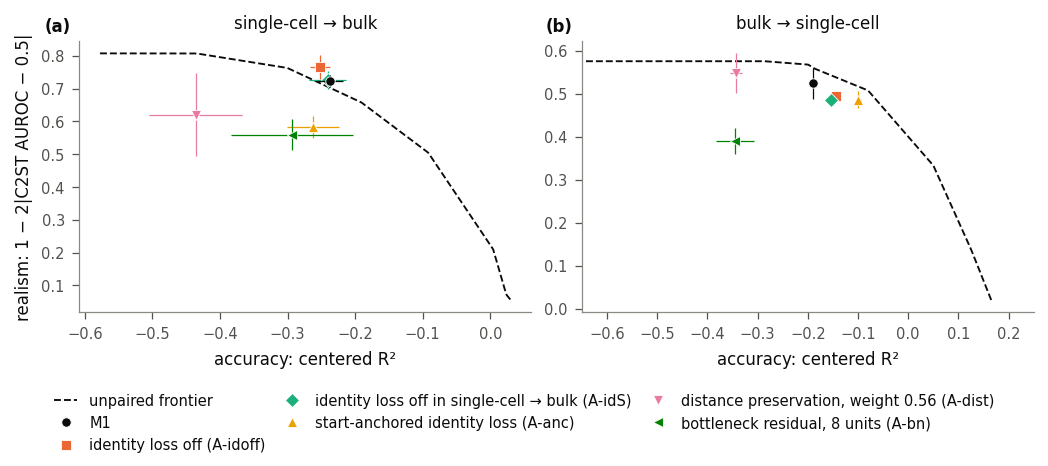

**None of the changes to the strictly unpaired model moves it beyond the unpaired frontier.** Each panel places translations of the 135 validation sources (14 donors) by accuracy and realism: (a) single-cell → bulk, (b) bulk → single-cell. Accuracy (x-axis) is the centered R², the R² of translated against real target profiles after removing each gene's training mean (median over validation pairs). Realism (y-axis) is 1 − 2|AUROC − 0.5|, where AUROC is that of a classifier two-sample test (C2ST) separating translated from real targets; 1 means indistinguishable. Higher is better on both axes. Each point is a last-quarter mean (the 11 evaluations at steps 15,000–20,000) of the averaged generator weights (an exponential moving average, decay 0.999), averaged over seeds 6–8, with error bars of ± 1 SD over the 3 seeds. Points show the locked strictly unpaired CycleGAN (M1, black circle) and its five track A variants, each with its own color and marker: the identity loss off in both directions (A-idoff), or in single-cell → bulk only (A-idS); an identity loss anchored to the baseline map the generator starts at (A-anc); distance preservation at the calibrated weight (A-dist); and an 8-unit bottleneck in the generator's residual branch (A-bn). The dashed curve is the unpaired frontier: the best realism reached at each accuracy by blending two of mean shift, ComBat, CORAL and the training-target mean, all fit on the same training halves as the models. In (b) the x-axis is cut at −0.65; the frontier continues to the left at nearly constant realism, and no model lies there. In (a), M1 and A-idS nearly coincide. Removing the identity loss sits on the frontier with M1; the other variants fall inside it.

In [9]:
# Figure 5.1: track A on the accuracy-realism plane (last-quarter means of the averaged weights) with the unpaired frontier.
from matplotlib.lines import Line2D
frontier = pd.read_csv(paths.results_dir(1) / "frontier_val_halves.csv")
fig, ax = figure("double", 3.0, 1, 2)
names = ["M1", *TRACK_A]
MARKERS = "osD^v<>P"
XL = {"S->B": None, "B->S": (-0.65, 0.25)}         # bulk -> single-cell: the frontier continues at nearly constant realism beyond the left edge
for a, d in zip(ax, tr.DIRECTIONS):
    env = envelope(frontier[(frontier.halving == 0) & (frontier.direction == d)])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=1)
    for i, n in enumerate(names):
        col = INK if n == "M1" else SERIES[i % len(SERIES)]
        a.errorbar(means.loc[n, f"{d} r2_centered"], means.loc[n, f"{d} realism"], xerr=sds.loc[n, f"{d} r2_centered"], yerr=sds.loc[n, f"{d} realism"],
                   fmt=MARKERS[i % len(MARKERS)], ms=4.5, mec="white", mew=0.4, color=col, lw=0.6, zorder=4 if n == "M1" else 3)
    if XL[d]:
        a.set_xlim(*XL[d])
    a.set(xlabel="accuracy: centered R²", ylabel="realism: 1 − 2|C2ST AUROC − 0.5|" if d == "S->B" else "", title=label(d))
handles = [Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier")] + \
          [Line2D([], [], ls="", marker=MARKERS[i % len(MARKERS)], ms=4.5, mec="white", mew=0.4, color=INK if n == "M1" else SERIES[i % len(SERIES)],
                  label=show_name(n)) for i, n in enumerate(names)]
fig.legend(handles=handles, loc="outside lower center", ncol=3, handlelength=1.6, columnspacing=1.0)
panel_labels(ax)
save_show(fig, FIG, "5.1_track_a_plane")
show_caption("5.1_track_a_plane")

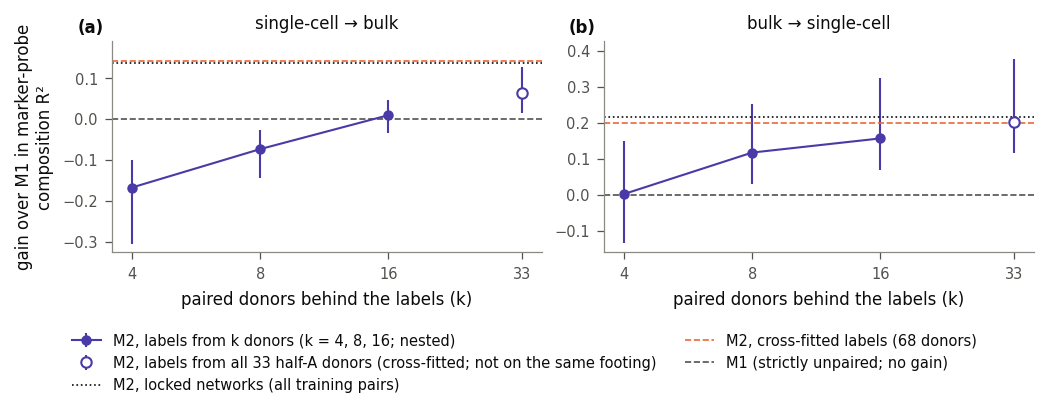

**Composition labels need enough paired donors: about 8 for bulk → single-cell, and at least 16 just to break even in single-cell → bulk.** Each panel shows the gain of the weakly paired model (M2) over the strictly unpaired M1 in marker-probe composition R² (higher is better), on the 135 validation pairs (14 donors): (a) single-cell → bulk, (b) bulk → single-cell. The marker probe is a ridge readout of the six cell-type fractions from 28 lineage marker genes, and composition R² is the mean over the six classes of the per-class R². The x-axis (log scale) is the number of paired donors k whose pairs trained the bulk composition network that produces the model's composition labels; all are drawn from half A, the 33 training donors whose single-cell profiles the model trains on. Filled points (k = 4, 8, 16) share one design: label networks trained on nested sets of donors from one 16-donor pool per seed, with the single-cell → bulk task term applied to the same 17 other half-A donors. The open point (k = 33) uses all of half A, with networks cross-fitted within it (each row read by a network that never saw its donor), and trains the single-cell → bulk term on twice as many rows, so it is not on the same footing. Points are means over the averaged generator weights kept at steps 15,000, 17,500 and 20,000 and over seeds 6–8; error bars are donor-bootstrap 95% CIs (1,000 resamples of the 14 donors). Horizontal lines are M2 with the locked composition networks (dotted; trained on all training pairs, including the labeled donors') and with labels cross-fitted over all 68 training donors (dashed orange); the dashed gray line at 0 is M1 (no gain). With labels from 4 or 8 donors the single-cell → bulk translations lose composition; in bulk → single-cell, labels from 8 donors already help.

In [10]:
# Figure 5.2: composition gain over M1 (marker probe) against the number of paired donors behind the labels, per direction.
# k = 4, 8, 16 share one design (nested labels; the single-cell -> bulk term trains on the same 17 other half-A donors);
# k = 33 (all of half A, cross-fitted within it) is not on the same footing and is drawn apart.
fig, ax = figure("double", 2.6, 1, 2)
kk = {f"B-k{k} labels from {k} donors": k for k in (4, 8, 16)}
k33 = "B-k33 labels from 33 donors"
def ci_of(g, n):
    lo, hi = (float(v) for v in g.loc[n, "Δ marker composition R² CI"].split(" to "))
    return g.loc[n, "Δ marker composition R²"], lo, hi
for a, d in zip(ax, tr.DIRECTIONS):
    g = ci_b[ci_b.direction == label(d)].set_index("condition")
    pts = np.array([ci_of(g, n) for n in kk])
    a.errorbar(list(kk.values()), pts[:, 0], yerr=[pts[:, 0] - pts[:, 1], pts[:, 2] - pts[:, 0]], fmt="o-", color=SERIES[6], lw=1, ms=4,
               label="M2, labels from k donors (k = 4, 8, 16; nested)")
    y, lo, hi = ci_of(g, k33)
    a.errorbar([33], [y], yerr=[[y - lo], [hi - y]], fmt="o", mfc="white", color=SERIES[6], lw=1, ms=5, label="M2, labels from all 33 half-A donors (cross-fitted; not on the same footing)")
    a.axhline(g.loc["M2", "Δ marker composition R²"], color=INK, lw=0.8, ls=":", label="M2, locked networks (all training pairs)")
    a.axhline(g.loc["B-cf cross-fitted labels", "Δ marker composition R²"], color=SERIES[1], lw=0.8, ls="--", label="M2, cross-fitted labels (68 donors)")
    a.axhline(0, **THRESHOLD, label="M1 (strictly unpaired; no gain)")
    top = max(pts[:, 2].max(), hi, g.loc["M2", "Δ marker composition R²"], g.loc["B-cf cross-fitted labels", "Δ marker composition R²"])
    a.set_ylim(top=top + 0.05)
    a.set(xscale="log", xlabel="paired donors behind the labels (k)", ylabel="gain over M1 in marker-probe\ncomposition R²" if d == "S->B" else "", title=label(d))
    a.set_xticks([4, 8, 16, 33]); a.set_xticklabels(["4", "8", "16", "33"]); a.minorticks_off()
h, l = ax[0].get_legend_handles_labels()
order = sorted(range(len(l)), key=lambda i: (not l[i].startswith("M2, labels"), i))   # the label-budget points first, then the reference lines
fig.legend([h[i] for i in order], [l[i] for i in order], loc="outside lower center", ncol=2)
panel_labels(ax)
save_show(fig, FIG, "5.2_label_budget")
show_caption("5.2_label_budget")

## 5. Conclusions

- **Without pairs, none of five changes moved the CycleGAN beyond the frontier:** removing the identity loss in one or both directions, a start-anchored identity loss, distance preservation and a bottleneck generator. The best did not hold up on fresh seeds (gain in margin +0.010 ± 0.025 over 3 seeds), and none raised the sample-specific component of the generators' moves in both directions.
- **The composition gain is about as large without each row's own donor's pair:** labels from networks that never saw the labeled row's donor (but did see other training donors' pairs) give a gain over M1 of +0.141 (95% CI 0.099–0.222) and +0.200 (95% CI 0.099–0.383), about the same as the locked networks (+0.137 and +0.216).
- **The labels need enough paired donors:**
  - **Bulk → single-cell:** labels from 8 donors already help (+0.117, 95% CI 0.029–0.251).
  - **Single-cell → bulk:** labels from 4–8 donors hurt (−0.168, 95% CI −0.305 to −0.100, and −0.074, 95% CI −0.144 to −0.026), and 16 donors break even (+0.009, 95% CI −0.034 to 0.047).
- **Given to a paired regression, the same pairs buy far more accuracy** (33 donors: centered R² 0.097 and 0.168 against −0.167 and −0.126), with lower realism and similar composition in single-cell → bulk and better realism and composition in bulk → single-cell.

**Implications.**
- No track A model is a candidate for the test set. The strictly unpaired result to report is the locked M1, on the frontier.
- If a track B model goes to test, the cross-fitted weakly paired model is the natural candidate: it is the honest-label setting designed for this question and the one most comparable with M2 (the 33-donor setting has a higher single-cell → bulk margin but lower composition, 0.474 against 0.552, and is not on the same footing). It would be reported as exploratory and weakly paired, against M1 and M2, never against H1, with every configuration compared on validation counted. The choice is fixed before the test evaluation.
- The exploitation check of Phase 2 (the attack-and-transfer test of the composition networks), planned for the test phase, applies to the weakly paired models trained here as well as to the locked M2.


## 6. Limitations

- **Exploratory and on validation only:** the settings were chosen on the donors that chose the locked models and informed Phase 4, so the numbers are optimistic. Donor-bootstrap CIs cover donor sampling, not training noise.
- **Three seeds and one donor pool per seed:** at k = 4–16 the seed SD also includes the choice of donors, and a 3-seed SD is itself noisy.
- **The label-budget curve has a confound in single-cell → bulk.** At k = 4–16 the single-cell → bulk term trains on 144 rows, and on 288 at k = 33 and with cross-fitting, so the last point is not on the same footing.
- **The paired comparator changes with k** (ridge from 8 donors, ridge + spread from 16).
- **Composition networks train for the Phase 2 number of epochs at every size,** so the small-k networks take fewer training steps than the full-size one.
- **Readouts use averaged weights,** so Phase 5 numbers are compared within this phase, not with the raw-weight readouts of Phases 3–4.
- **Track A tried one weight per new loss and one bottleneck size.**
- **All margins use the H1 realism measure,** the only one Phase 4 found usable in single-cell → bulk; any statement relative to the frontier inherits that.


## 7. Reproducibility

- **Runtime:** the 45 runs (3 equivalence runs, 36 on seeds 6–8, 6 confirmation runs on seeds 9–11) took about 12 hours with 6 workers of 4 threads each on a 24-thread Intel Core Ultra 9 275HX. Runs are deterministic.
- **Caches and models:**
  - runs are cached in `data/processed/phase5/` under a key covering the code (`dgm/translation.py`, `dgm/labels.py` and the modules they use), the earlier frontier and model registries, the pairs file and the library versions; delete the cache to recompute;
  - the composition networks are in `data/models/phase5/`, with hashes, training donors and fold maps in `results/phase5/models.json`;
  - with a full cache the notebook runs in about 30 minutes.
- **Tests:** `python -m tests.test_phase5`.

**Outputs in `results/phase5/`:**
- `label_networks_val.csv` (Table 5.1), `distance_precheck_val.csv` (Table 5.2);
- `runs_val.csv`, `means_val.csv`, `sd_val.csv` (every readout per run, and per condition; Tables 5.3 and 5.7);
- `sample_specific_val.csv` (Table 5.4), `track_a_ci_val.csv` (Table 5.5), `confirmation_val.csv` (Table 5.6);
- `track_b_ci_val.csv` (Table 5.8), `ridge_spread_k_val.csv` (Table 5.9);
- `figures/`: Figures 5.1–5.2 as PNG and PDF, with their captions in `captions.md`.

## References

- Benaim, S. & Wolf, L. One-sided unsupervised domain mapping. *NeurIPS* (2017).
- Hoffman, J., Tzeng, E., Park, T., Zhu, J.-Y., Isola, P., Saenko, K., Efros, A. A. & Darrell, T. CyCADA: cycle-consistent adversarial domain adaptation. *ICML* (2018).
- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Mao, X., Li, Q., Xie, H., Lau, R. Y. K., Wang, Z. & Smolley, S. P. Least squares generative adversarial networks. *ICCV*, 2813–2821 (2017).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).